In [ ]:
# Locate this checkout when launched from the repository or notebook folder.
from pathlib import Path
import sys
_REPOSITORY_ROOT = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "aerosandbox/__init__.py").is_file()
    and (p / "studies/TSher_Improvements").is_dir()
)
_STUDY_DIRECTORY = _REPOSITORY_ROOT / "studies/TSher_Improvements/aerodynamics"
for _path in [_REPOSITORY_ROOT, _STUDY_DIRECTORY]:
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))


The accepted two-correction normal-flow model is now available as `asb.NormalFlowLiftingLine`. Script examples below use that public class. The study-only `CorrectedLiftingLine` subclass retains the original ablations. Stored results and their original source hashes are retained from the earlier experiment; promotion regression checks verify the selected model against them. Re-run the notebook to refresh timings and metadata for this layout.

# Flying wing: inexpensive LiftingLine corrections

Compare the existing **quasi-linear `asb.LiftingLine`** with explicit alternatives for its
2-pi sectional slope and NeuralFoil/circulation coupling. Priorities are the drag polar,
high-lift coverage, and overall lift accuracy, with predictable computational cost and an
interface usable in `CTOL_scoring`. No AeroBuildup, VLM, or nonlinear lifting-line solve
is needed here. No experimental CL cap, angle offset, or drag correction is fitted.

The reusable implementation is `lifting_line_corrections.CorrectedLiftingLine`, a subclass
of `asb.LiftingLine`. AeroSandbox library files and the original comparison notebook are
unchanged. This notebook and implementation were generated with Codex and require human
review before an upstream contribution or design-critical use.

In [1]:
from pathlib import Path
import sys, json, hashlib, importlib.metadata, os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import aerosandbox as asb
from IPython.display import display

candidates = [Path('.'), Path('studies/TSher_Improvements/aerodynamics')]
study = next(p.resolve() for p in candidates if (p / 'lifting_line_corrections.py').is_file())
if str(study) not in sys.path:
    sys.path.insert(0, str(study))
from lifting_line_corrections import CorrectedLiftingLine
from lifting_line_correction_study import (
    VARIANTS, OUTPUT, ASSETS, ROOT, flying_wing, flying_reference,
    clark_y_wing, clark_reference, sweep, metrics, rising_branch, solver,
)
OUTPUT.mkdir(exist_ok=True)
data_manifest = json.loads((study / 'lifting_line_correction_data/sources.json').read_text())
for filename, expected in data_manifest['sha256'].items():
    actual = hashlib.sha256((study / 'lifting_line_correction_data' / filename).read_bytes()).hexdigest()
    assert actual == expected, f'Reference source changed: {filename}'
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 5)

## What is changed mathematically?

The original calculation approximately solves

\[
 [D-\operatorname{diag}(a)B]\Gamma=c_l(\alpha_g),\qquad
 \alpha_e=\alpha_g+B\Gamma,
\]

where $B$ maps circulation to induced angle in radians, $D\Gamma$ is the sectional
Kutta-Joukowski lift coefficient, and $a=2\pi$ per radian. NeuralFoil is then evaluated
again at $\alpha_e$. In nonlinear regions, $D\Gamma$ and $c_l(\alpha_e)$ can disagree.

The alternatives use a finite-difference NeuralFoil **attached slope** around +/-2 degrees,
or a **local tangent** around +/-0.5 degrees. Variable sectional slopes scale matrix **rows**:
the receiving section's slope multiplies its whole induced-angle equation. The local
Jacobian slope is smoothly limited to 0.5--12 /rad; NeuralFoil CL is not clipped.

A fixed number of residual corrections then applies

\[
 \Delta\Gamma=[D-\operatorname{diag}(a)B]^{-1}
 [c_l(\alpha_e)-D\Gamma],\qquad
 \Gamma\leftarrow\Gamma+0.8\,\Delta\Gamma.
\]

These are explicit, unrolled linear solves, not an implicit nonlinear optimization.
The number of solves is exactly **1 + corrections**. Residuals are reported; two steps
must not be assumed converged near stall. The 0.8 x 2-pi case is a declared ablation,
not a fitted coefficient or the recommended default.

The **normal-flow** hypothesis additionally uses flow and chord normal to the bound
vortex: $c_\perp=S_i/\ell_i$, $V_\perp^2=V_f^2+V_n^2$,
$\alpha_e=\mathrm{atan2}(V_n,V_f)$, $Re=V_\perp c_\perp/\nu$, and
$D=2\ell_i/(V_\perp S_i)$. The same sectional force convention is used for profile drag
and pitching moment. The supplied airfoil is interpreted as the sectional polar in that
plane; transforming the airfoil shape itself for sweep is outside this prototype.
This convention is a hypothesis to test, not a claim that sweep physics is solved.

All force changes come from the corrected circulation and sectional aerodynamics;
induced velocities are recomputed consistently. There is no force-only lift rescaling.

In [2]:
display(pd.DataFrame([
    {'variant': name, **(options or {'implementation': 'unmodified asb.LiftingLine'})}
    for name, options in VARIANTS.items()
]).fillna('default'))

,variant,implementation,slope_model,slope_scale,circulation_corrections,kinematics
0,Original LiftingLine,unmodified asb.LiftingLine,default,default,default,default
1,"0.8 x 2pi, no correction",default,two_pi,0.8,0.0,default
2,"NF attached slope, no correction",default,attached,default,0.0,default
3,"NF local slope, no correction",default,local,default,0.0,default
4,2pi + 2 corrections,default,two_pi,default,2.0,default
5,NF attached + 2 corrections,default,attached,default,2.0,default
6,NF local + 2 corrections,default,local,default,2.0,default
7,"Normal flow, NF attached + 2",default,attached,default,2.0,normal
8,"Normal flow, NF attached + 4",default,attached,default,4.0,normal


## Same flying wing and digitized reference as the original notebook

The geometry, NACA 64_1_A612 coordinates, sea-level speed of 91.3 m/s, and coefficient
references match the existing study. Reference: [NACA RM A50K27](https://ntrs.nasa.gov/citations/19930086568).
The workbook is the repository's existing digitization, courtesy of John Yost.

**CLmax limitation:** the supplied CL(alpha) points end at 13.17 degrees with CL still
rising. The CD(CL) digitization extends to a higher CL, but does not establish an alpha
or a stall peak. We can measure lift error, drag-polar error, and failure to reach observed
lift; we cannot assign a true experimental CLmax error for this flying-wing digitization.

Drag is compared at the **same lift coefficient** on each model's increasing pre-peak
branch, without extrapolation. A common-CL score uses exactly the same reference nodes
for all invertible branches; the separate coverage score shows how much high-lift polar
each method can represent. Comparing each model's own covered-node RMSE alone would
unfairly reward a model that cannot reach the difficult high-lift data. Cm is compared
directly against CL, without inventing missing moment-point angles of attack.

In [3]:
airplane = flying_wing()
reference = flying_reference()
for key, frame in reference.items():
    frame.to_csv(OUTPUT / f'flying_wing_reference_{key}.csv', index=False)
display(pd.DataFrame([{'reference': key, 'nodes': len(frame), 'min_CL': frame.CL.min(),
                       'max_CL': frame.CL.max()} for key, frame in reference.items()]))
SPAN = 12  # Per semispan for this two-section wing: 24 total strips.
MODEL_SIZE = 'medium'
ALPHAS = np.unique(np.r_[np.arange(-8.0, 22.01, 1.0), reference['lift'].alpha.to_numpy()])
print(f'{len(ALPHAS)} angle nodes; {2 * SPAN} strips; NeuralFoil {MODEL_SIZE}.')

,reference,nodes,min_CL,max_CL
0,lift,20,-0.10105,0.99789
1,drag,20,0.05122,1.08613
2,moment,20,-0.10600,1.01000


51 angle nodes; 24 strips; NeuralFoil medium.


In [4]:
predictions = sweep(airplane, ALPHAS, velocity=91.3, spanwise_resolution=SPAN, model_size=MODEL_SIZE)
predictions.to_csv(OUTPUT / 'flying_wing_predictions.csv', index=False)
summary = metrics(predictions, reference)
baseline = summary[summary.variant == 'Original LiftingLine'].iloc[0]
summary['lift_RMSE_ratio'] = summary.CL_alpha_RMSE / baseline.CL_alpha_RMSE
summary['common_drag_RMSE_ratio'] = summary.CD_common_CL_RMSE / baseline.CD_common_CL_RMSE
summary['runtime_ratio'] = summary.seconds_per_point / baseline.seconds_per_point
summary.to_csv(OUTPUT / 'flying_wing_metrics.csv', index=False)
display(summary)

Original LiftingLine: 51 points complete
0.8 x 2pi, no correction: 51 points complete
NF attached slope, no correction: 51 points complete
NF local slope, no correction: 51 points complete
2pi + 2 corrections: 51 points complete
NF attached + 2 corrections: 51 points complete
NF local + 2 corrections: 51 points complete
Normal flow, NF attached + 2: 51 points complete
Normal flow, NF attached + 4: 51 points complete


,variant,CL_alpha_RMSE,CD_at_CL_RMSE,CD_common_CL_RMSE,CD_common_nodes,Cm_common_CL_RMSE,CD_polar_coverage,CD_polar_nodes,predicted_peak_CL,predicted_peak_alpha,resolved_interior_peak,observed_high_CL_shortfall,seconds_per_point,worst_sectional_residual,lift_RMSE_ratio,common_drag_RMSE_ratio,runtime_ratio
0,Original LiftingLine,0.12539,0.00455,0.00455,11,0.04471,11/20,11,0.81127,14.0000,True,0.27486,0.31809,NaN,1.00000,1.00000,1.00000
1,"0.8 x 2pi, no correction",0.10829,0.00329,0.00329,11,0.03940,11/20,11,0.83657,14.0000,True,0.24956,0.28770,1.12139,0.86358,0.72276,0.90446
2,"NF attached slope, no correction",0.12407,0.00441,0.00441,11,0.04451,11/20,11,0.81335,14.0000,True,0.27278,0.41046,1.13833,0.98946,0.97049,1.29038
3,"NF local slope, no correction",0.09422,0.00346,0.00258,11,0.03782,14/20,14,0.93297,15.0000,True,0.15316,0.40672,2.19186,0.75143,0.56820,1.27863
4,2pi + 2 corrections,0.10297,0.00384,0.00285,11,0.04217,13/20,13,0.89019,15.0000,True,0.19594,0.53573,0.48254,0.82114,0.62578,1.68421
5,NF attached + 2 corrections,0.10292,0.00384,0.00285,11,0.04213,13/20,13,0.89022,15.0000,True,0.19591,0.66941,0.48128,0.82076,0.62569,2.10445
6,NF local + 2 corrections,0.10191,0.00371,0.00282,11,0.04162,13/20,13,0.89766,16.0000,True,0.18847,1.05403,1.22241,0.81271,0.61980,3.31360
7,"Normal flow, NF attached + 2",0.07192,0.00370,0.00292,11,0.02809,15/20,15,0.95847,14.0000,True,0.12766,0.68298,0.61340,0.57355,0.64102,2.14711
8,"Normal flow, NF attached + 4",0.07142,0.00375,0.00292,11,0.02796,15/20,15,0.95676,13.1674,True,0.12937,0.99592,0.42253,0.56956,0.64116,3.13091


## Select a candidate transparently

Prefer an alternative that improves both lift RMSE and common-CL drag RMSE over the
baseline, while reducing the shortfall relative to observed high lift. Among those, select
the smallest lift RMSE. If none qualifies, show the best normalized lift/drag tradeoff and
state that no joint improvement was found. This is exploratory model selection on the
flying-wing data, not a held-out validation result. The independent Clark Y case below
uses the declared variants without retuning their parameters.

For a runtime-sensitive script, also choose the cheapest joint-improvement variant whose lift RMSE is within 5% of the best-fitting candidate. This tolerance is a model-selection tradeoff, not an airfoil calibration or a validation guarantee.

In [5]:
alternatives = summary[summary.variant != 'Original LiftingLine'].copy()
joint = alternatives[(alternatives.lift_RMSE_ratio < 1) &
                     (alternatives.common_drag_RMSE_ratio < 1) &
                     (alternatives.observed_high_CL_shortfall < baseline.observed_high_CL_shortfall)]
if len(joint):
    SELECTED = joint.sort_values(['CL_alpha_RMSE', 'CD_common_CL_RMSE']).iloc[0].variant
    print('Joint improvement on the flying-wing data:', SELECTED)
else:
    alternatives['tradeoff'] = alternatives.lift_RMSE_ratio + alternatives.common_drag_RMSE_ratio
    SELECTED = alternatives.sort_values('tradeoff').iloc[0].variant
    print('No joint improvement; selected a tradeoff for inspection:', SELECTED)
SELECTED_OPTIONS = VARIANTS[SELECTED].copy()
print('Options:', SELECTED_OPTIONS)
display(summary[['variant', 'CL_alpha_RMSE', 'CD_common_CL_RMSE', 'CD_polar_coverage',
                 'predicted_peak_CL', 'predicted_peak_alpha', 'runtime_ratio', 'worst_sectional_residual']])

if len(joint):
    near_best = joint[joint.CL_alpha_RMSE <= 1.05 * joint.CL_alpha_RMSE.min()]
    PRACTICAL = near_best.sort_values('seconds_per_point').iloc[0].variant
else:
    PRACTICAL = SELECTED
PRACTICAL_OPTIONS = VARIANTS[PRACTICAL].copy()
print('Lower-cost candidate within 5% of the best joint lift RMSE:', PRACTICAL)
print('Script options:', PRACTICAL_OPTIONS)


Joint improvement on the flying-wing data: Normal flow, NF attached + 4
Options: {'kinematics': 'normal', 'slope_model': 'attached', 'circulation_corrections': 4}


,variant,CL_alpha_RMSE,CD_common_CL_RMSE,CD_polar_coverage,predicted_peak_CL,predicted_peak_alpha,runtime_ratio,worst_sectional_residual
0,Original LiftingLine,0.12539,0.00455,11/20,0.81127,14.0000,1.00000,NaN
1,"0.8 x 2pi, no correction",0.10829,0.00329,11/20,0.83657,14.0000,0.90446,1.12139
2,"NF attached slope, no correction",0.12407,0.00441,11/20,0.81335,14.0000,1.29038,1.13833
3,"NF local slope, no correction",0.09422,0.00258,14/20,0.93297,15.0000,1.27863,2.19186
4,2pi + 2 corrections,0.10297,0.00285,13/20,0.89019,15.0000,1.68421,0.48254
5,NF attached + 2 corrections,0.10292,0.00285,13/20,0.89022,15.0000,2.10445,0.48128
6,NF local + 2 corrections,0.10191,0.00282,13/20,0.89766,16.0000,3.31360,1.22241
7,"Normal flow, NF attached + 2",0.07192,0.00292,15/20,0.95847,14.0000,2.14711,0.61340
8,"Normal flow, NF attached + 4",0.07142,0.00292,15/20,0.95676,13.1674,3.13091,0.42253


Lower-cost candidate within 5% of the best joint lift RMSE: Normal flow, NF attached + 2
Script options: {'kinematics': 'normal', 'slope_model': 'attached', 'circulation_corrections': 2}


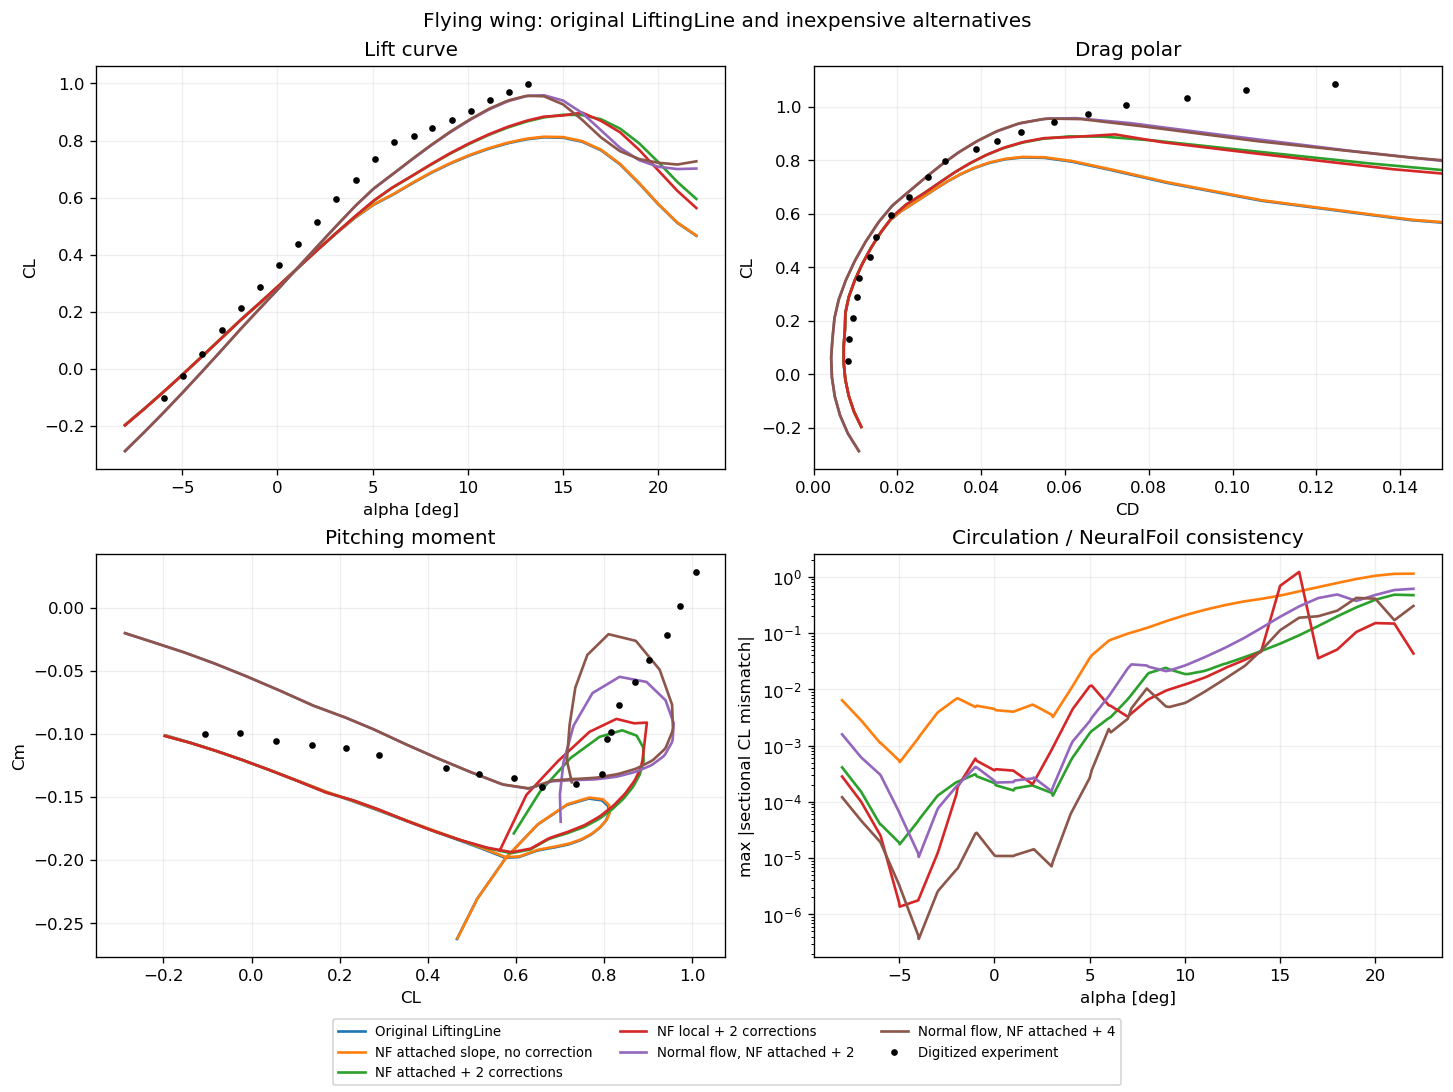

In [6]:
highlight = list(dict.fromkeys(['Original LiftingLine', 'NF attached slope, no correction',
                               'NF attached + 2 corrections', 'NF local + 2 corrections', PRACTICAL, SELECTED]))
colors = dict(zip(highlight, plt.get_cmap('tab10').colors))
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for name in highlight:
    frame = predictions[predictions.variant == name].sort_values('alpha')
    style = dict(label=name, linewidth=1.6, color=colors[name])
    axes[0, 0].plot(frame.alpha, frame.CL, **style)
    axes[0, 1].plot(frame.CD, frame.CL, **style)
    axes[1, 0].plot(frame.CL, frame.Cm, **style)
    if frame.max_sectional_residual.notna().any():
        axes[1, 1].semilogy(frame.alpha, np.maximum(frame.max_sectional_residual, 1e-12), **style)
axes[0, 0].plot(reference['lift'].alpha, reference['lift'].CL, 'ko', ms=3, label='Digitized experiment')
axes[0, 1].plot(reference['drag'].CD, reference['drag'].CL, 'ko', ms=3)
axes[1, 0].plot(reference['moment'].CL, reference['moment'].Cm, 'ko', ms=3)
for ax, title, x, y in [
    (axes[0, 0], 'Lift curve', 'alpha [deg]', 'CL'),
    (axes[0, 1], 'Drag polar', 'CD', 'CL'),
    (axes[1, 0], 'Pitching moment', 'CL', 'Cm'),
    (axes[1, 1], 'Circulation / NeuralFoil consistency', 'alpha [deg]', 'max |sectional CL mismatch|'),
]:
    ax.set(title=title, xlabel=x, ylabel=y)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncols=3, fontsize=8)
axes[0, 1].set_xlim(0, 0.15)
fig.suptitle('Flying wing: original LiftingLine and inexpensive alternatives')
fig.savefig(OUTPUT / 'flying_wing_lifting_line_corrections.png', dpi=180)
plt.show()

## Resolve predicted peaks and check mesh dependence

A 0.5-degree scan from 6 to 22 degrees sharpens the sampled positive-lift peak for the
baseline and selected candidate. The figure's horizontal reference line is the highest
digitized CL in the polar, **not a measured CLmax**. A second mesh doubles the spanwise
resolution at 4, 10, and 15 degrees. Small changes support local numerical consistency;
they do not prove convergence in separated flow or validate a whole stall curve.

In [7]:
peak_variants = list(dict.fromkeys(['Original LiftingLine', SELECTED, PRACTICAL]))
fine_peaks = sweep(airplane, np.arange(6, 22.01, 0.5), 91.3, variants=peak_variants,
                   spanwise_resolution=SPAN, model_size=MODEL_SIZE)
fine_peaks.to_csv(OUTPUT / 'flying_wing_peak_scan.csv', index=False)
peak_table = metrics(fine_peaks, reference)[['variant', 'predicted_peak_CL', 'predicted_peak_alpha',
                                           'resolved_interior_peak', 'observed_high_CL_shortfall']]
display(peak_table)
mesh_rows = []
for name in peak_variants:
    for alpha in [4.0, 10.0, 15.0]:
        coarse = solver(name, airplane, asb.OperatingPoint(velocity=91.3, alpha=alpha),
                        spanwise_resolution=SPAN, model_size=MODEL_SIZE).run()
        refined = solver(name, airplane, asb.OperatingPoint(velocity=91.3, alpha=alpha),
                         spanwise_resolution=2 * SPAN, model_size=MODEL_SIZE).run()
        mesh_rows.append(dict(variant=name, alpha=alpha, CL_base=float(coarse['CL']),
                              delta_CL=float(refined['CL'] - coarse['CL']),
                              CD_base=float(coarse['CD']), delta_CD=float(refined['CD'] - coarse['CD'])))
mesh = pd.DataFrame(mesh_rows)
mesh.to_csv(OUTPUT / 'mesh_sensitivity.csv', index=False)
display(mesh)

Original LiftingLine: 33 points complete
Normal flow, NF attached + 4: 33 points complete
Normal flow, NF attached + 2: 33 points complete


,variant,predicted_peak_CL,predicted_peak_alpha,resolved_interior_peak,observed_high_CL_shortfall
0,Original LiftingLine,0.81198,14.5,True,0.27415
1,"Normal flow, NF attached + 4",0.95801,13.5,True,0.12812
2,"Normal flow, NF attached + 2",0.95876,13.5,True,0.12737


,variant,alpha,CL_base,delta_CL,CD_base,delta_CD
0,Original LiftingLine,4.0,0.52513,-0.01969,0.01583,0.00082
1,Original LiftingLine,10.0,0.74496,-0.02737,0.03471,0.00108
2,Original LiftingLine,15.0,0.80994,-0.02878,0.05501,0.00081
3,"Normal flow, NF attached + 4",4.0,0.56456,-0.02488,0.01533,0.00085
4,"Normal flow, NF attached + 4",10.0,0.86943,-0.03103,0.03870,0.00184
5,"Normal flow, NF attached + 4",15.0,0.92660,-0.03386,0.07920,0.00514
6,"Normal flow, NF attached + 2",4.0,0.56431,-0.02486,0.01532,0.00085
7,"Normal flow, NF attached + 2",10.0,0.86744,-0.03094,0.03852,0.00182
8,"Normal flow, NF attached + 2",15.0,0.94001,-0.02534,0.07554,0.00355


## Independent single-wing data: Clark Y, aspect ratio 6

[NACA TR 431, *Characteristics of Clark Y Airfoils of Small Aspect Ratios*](https://ntrs.nasa.gov/citations/19930091504)
provides a fully isolated rectangular wing. Its Table I supplies the section ordinates,
and Table II supplies lift and **total wing drag** through stall at **-20 degrees yaw**.
The angle of attack and drag have the report's tunnel-wall corrections. These are not
two-dimensional airfoil coefficients or a complete aircraft.

We transcribe the printed table without fitting or graph digitization. The source PDF,
coordinates, and data are included in `lifting_line_correction_data`. The model uses a
14.14-inch reference chord, span = 6 chords, and 80 mph at sea level, approximately the
reported Re = 860,000. Use beta = -20 degrees for Table II. Moment comparisons are omitted
here because the report's chord-axis moment convention needs separate reconciliation.
Transition/turbulence and historical model details remain uncertainty sources.

The measured **sampled** Table II peak is 1.194 at 16.2 degrees, with lower surrounding
points. This supports a peak comparison, unlike the truncated flying-wing lift data.
The separate **zero-yaw** Table IX value is CLmax = 1.240. Its 15-degree entry refers
to maximum resultant force, so it is not used as a maximum-lift angle target. Do not mix the
two operating conditions. Two-dimensional section polars cannot reproduce every finite-wing
separation or post-stall vortex mechanism, even with perfect circulation convergence.

Original LiftingLine: 32 points complete
0.8 x 2pi, no correction: 32 points complete
NF attached slope, no correction: 32 points complete
NF local slope, no correction: 32 points complete
2pi + 2 corrections: 32 points complete
NF attached + 2 corrections: 32 points complete
NF local + 2 corrections: 32 points complete
Normal flow, NF attached + 2: 32 points complete
Normal flow, NF attached + 4: 32 points complete


,variant,CL_alpha_RMSE,CD_common_CL_RMSE,CD_polar_coverage,predicted_peak_CL,peak_alpha,sampled_peak_error
0,Original LiftingLine,0.23944,0.01059,5/11,0.95812,12.3,-0.23588
1,"0.8 x 2pi, no correction",0.21836,0.01097,5/11,1.00274,12.3,-0.19126
2,"NF attached slope, no correction",0.24339,0.01040,5/11,0.95059,12.3,-0.24341
3,"NF local slope, no correction",0.15121,0.01109,10/11,1.19124,13.3,-0.00276
4,2pi + 2 corrections,0.11823,0.01127,8/11,1.13583,15.2,-0.05817
5,NF attached + 2 corrections,0.11901,0.01127,8/11,1.13433,15.2,-0.05967
6,NF local + 2 corrections,0.10408,0.01127,9/11,1.15464,15.2,-0.03936
7,"Normal flow, NF attached + 2",0.08292,0.01279,11/11,1.19730,15.2,0.00330
8,"Normal flow, NF attached + 4",0.07412,0.01279,11/11,1.22929,16.0,0.03529


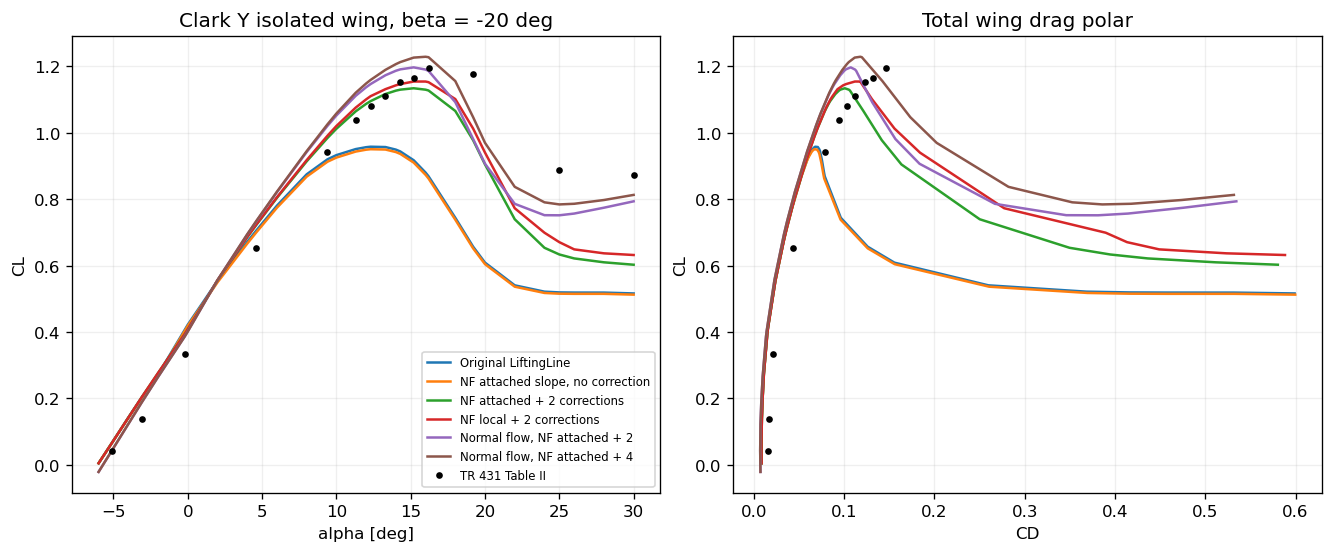

In [8]:
clark_plane = clark_y_wing()
clark_ref = clark_reference()
clark_alphas = np.unique(np.r_[np.arange(-6, 30.01, 2), clark_ref['lift'].alpha])
clark_predictions = sweep(clark_plane, clark_alphas, velocity=80 * 0.44704,
                           beta=-20, spanwise_resolution=SPAN, model_size=MODEL_SIZE)
clark_predictions.to_csv(OUTPUT / 'clark_y_yaw20_predictions.csv', index=False)
clark_summary = metrics(clark_predictions, clark_ref)
# Peak comparisons are confined to the first stall window, alpha <= 25 deg.
peak_rows = []
for name, frame in clark_predictions[clark_predictions.alpha.between(0, 25)].groupby('variant', sort=False):
    peak = frame.loc[frame.CL.idxmax()]
    interior = 0 < peak.alpha < 25
    peak_rows.append(dict(variant=name, predicted_peak_CL=peak.CL, peak_alpha=peak.alpha,
                          sampled_peak_error=peak.CL - 1.194 if interior else np.nan,
                          resolved_interior_peak=interior))
clark_peak_summary = pd.DataFrame(peak_rows)
clark_summary = clark_summary.drop(columns=['predicted_peak_CL', 'predicted_peak_alpha', 'resolved_interior_peak'])
clark_summary = clark_summary.merge(clark_peak_summary, on='variant', validate='one_to_one')
clark_summary.to_csv(OUTPUT / 'clark_y_yaw20_metrics.csv', index=False)
display(clark_summary[['variant', 'CL_alpha_RMSE', 'CD_common_CL_RMSE', 'CD_polar_coverage',
                      'predicted_peak_CL', 'peak_alpha', 'sampled_peak_error']])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for name in highlight:
    frame = clark_predictions[clark_predictions.variant == name]
    axes[0].plot(frame.alpha, frame.CL, label=name, color=colors[name])
    axes[1].plot(frame.CD, frame.CL, label=name, color=colors[name])
axes[0].plot(clark_ref['lift'].alpha, clark_ref['lift'].CL, 'ko', ms=3, label='TR 431 Table II')
axes[1].plot(clark_ref['drag'].CD, clark_ref['drag'].CL, 'ko', ms=3)
axes[0].set(xlabel='alpha [deg]', ylabel='CL', title='Clark Y isolated wing, beta = -20 deg')
axes[1].set(xlabel='CD', ylabel='CL', title='Total wing drag polar')
axes[0].legend(fontsize=7)
fig.savefig(OUTPUT / 'clark_y_independent_comparison.png', dpi=180)
plt.show()

In [9]:
zero_yaw_predictions = sweep(clark_plane, np.arange(0, 26.01, 1), 80 * 0.44704,
                             variants=peak_variants, beta=0,
                             spanwise_resolution=SPAN, model_size=MODEL_SIZE)
zero_yaw_predictions.to_csv(OUTPUT / 'clark_y_zero_yaw_peak_scan.csv', index=False)
zero_yaw_rows = []
for name, frame in zero_yaw_predictions.groupby('variant', sort=False):
    peak = frame.loc[frame.CL.idxmax()]
    interior = frame.alpha.min() < peak.alpha < frame.alpha.max()
    zero_yaw_rows.append(dict(variant=name, predicted_peak_CL=peak.CL, peak_alpha=peak.alpha,
                              measured_CLmax=1.240,
                              CLmax_error=peak.CL - 1.240 if interior else np.nan,
                              resolved_interior_peak=interior,
                              measured_CDmin=0.0151, predicted_CDmin=frame.CD.min()))
zero_yaw = pd.DataFrame(zero_yaw_rows)
zero_yaw.to_csv(OUTPUT / 'clark_y_zero_yaw_peak_metrics.csv', index=False)
display(zero_yaw)

Original LiftingLine: 27 points complete
Normal flow, NF attached + 4: 27 points complete
Normal flow, NF attached + 2: 27 points complete


,variant,predicted_peak_CL,peak_alpha,measured_CLmax,CLmax_error,resolved_interior_peak,measured_CDmin,predicted_CDmin
0,Original LiftingLine,1.08263,12.0,1.24,-0.15737,True,0.0151,0.01764
1,"Normal flow, NF attached + 4",1.39967,16.0,1.24,0.15967,True,0.0151,0.01693
2,"Normal flow, NF attached + 2",1.36227,15.0,1.24,0.12227,True,0.0151,0.01695


## Script/CTOL usage and differentiability

Only replace the analysis class and add explicit experimental options. Standard geometry,
OperatingPoint, n_crit, xtr_upper/lower, and spanwise-resolution arguments are preserved.
`run_with_stability_derivatives`, CL/CD/Cm, x_np, vortex_strengths, vortex_centers, and
the per-wing spanwise arrays remain available. Scalar alpha sweeps still use a Python loop.

The following call has the same structure as `CTOL_scoring`'s lifting-line helper:

In [10]:
analysis = asb.NormalFlowLiftingLine(
    airplane=airplane,
    op_point=asb.OperatingPoint(velocity=91.3, alpha=4),
    spanwise_resolution=SPAN, model_size=MODEL_SIZE,
    n_crit=5.0, xtr_upper=0.3, xtr_lower=0.3,
    circulation_corrections=2,
)
ctol_style = analysis.run_with_stability_derivatives(alpha=True, beta=False, p=False, q=False, r=False)
display(pd.Series({key: float(ctol_style[key]) for key in ['L', 'CL', 'D', 'CD', 'Cm', 'x_np', 'CLa', 'Cma']}))
assert len(analysis.vortex_strengths) == 2 * SPAN
assert np.isfinite([ctol_style[key] for key in ['L', 'CL', 'D', 'CD', 'Cm', 'x_np']]).all()

L       2647.61523
CL         0.54171
D         78.27912
CD         0.01602
Cm        -0.13097
x_np       0.61852
CLa        3.90202
Cma       -0.40875
dtype: float64

The small optimization below verifies symbolic alpha, chord, and span through the actual
`asb.Opti` solver. It sizes a wing with a tail at fixed reference area and lift while minimizing
drag; it is an API demonstration, not the CTOL mission model or a validated aircraft design.
The separate tests also compare CasADi derivatives against finite differences and NumPy
evaluations, check force/spanwise compatibility, and exercise fins and fuselages.

In [11]:
def demo_airplane(root, span):
    main = asb.Airfoil('naca2412')
    tail = asb.Airfoil('naca0012')
    return asb.Airplane(name='CTOL interface demonstration',
        xyz_ref=[0.25 * root, 0, 0], s_ref=0.8 * root * span,
        c_ref=(2 / 3) * root * (1 + 0.6 + 0.6**2) / (1 + 0.6), b_ref=span,
        wings=[
            asb.Wing(name='Wing', symmetric=True, xsecs=[
                asb.WingXSec(xyz_le=[0, 0, 0], chord=root, airfoil=main),
                asb.WingXSec(xyz_le=[0.15, span / 2, 0], chord=0.6 * root, airfoil=main),
            ]),
            asb.Wing(name='Tail', symmetric=True, xsecs=[
                asb.WingXSec(xyz_le=[2.1, 0, 0.1], chord=0.35, twist=-2, airfoil=tail),
                asb.WingXSec(xyz_le=[2.2, 0.7, 0.1], chord=0.25, twist=-2, airfoil=tail),
            ]),
        ])

opti = asb.Opti()
alpha = opti.variable(init_guess=4, lower_bound=-2, upper_bound=12)
root = opti.variable(init_guess=0.6, lower_bound=0.35, upper_bound=1.0)
span = opti.variable(init_guess=3.2, lower_bound=2.0, upper_bound=5.0)
demo = demo_airplane(root, span)
demo_aero = asb.NormalFlowLiftingLine(airplane=demo,
    op_point=asb.OperatingPoint(velocity=20, alpha=alpha), model_size='small',
    spanwise_resolution=3, n_crit=5, xtr_upper=0.3, xtr_lower=0.3,
    circulation_corrections=2).run()
opti.subject_to([demo.s_ref == 1.5, demo_aero['L'] == 150])
opti.minimize(demo_aero['D'])
sol = opti.solve(verbose=False, max_iter=150, max_runtime=60,
                  options={'ipopt.hessian_approximation': 'limited-memory'})
demo_result = {key: float(sol(value)) for key, value in
    dict(alpha=alpha, root_chord=root, span=span, CL=demo_aero['CL'], CD=demo_aero['CD'],
         L=demo_aero['L'], D=demo_aero['D'], Cm=demo_aero['Cm']).items()}
assert abs(demo_result['L'] - 150) < 1e-3
assert abs(0.8 * demo_result['root_chord'] * demo_result['span'] - 1.5) < 1e-5
display(pd.Series(demo_result))
_ = (OUTPUT / 'ctol_interface_optimization.json').write_text(json.dumps(demo_result, indent=2))

alpha           2.21818
root_chord      0.37500
span            5.00000
CL              0.40816
CD              0.01653
L             150.00000
D               6.07462
Cm             -0.00208
dtype: float64

## Interpretation

Changing the 2-pi constant and fixing circulation/NeuralFoil consistency are separate
experiments. A lower drag error over common lift does not establish a better high-lift
envelope; inspect both coverage and predicted peak. A smaller consistency residual is
useful but is not itself an experimental accuracy metric. Inspect moment and mesh changes
as well as lift/drag before using a candidate in an optimization.

The selected flying-wing candidate is not automatically the best Clark Y candidate.
If the independent peak error or drag error gets worse, retain that finding rather than
retuning parameters to hide it. Results from two wings cannot establish a universally
more accurate lifting-line model, especially near separated swept-wing flow.

For CTOL integration, import `CorrectedLiftingLine` from the study module and pass the
selected options shown above. Keep the existing production solver available for comparison.
The prototype does not silently replace `asb.LiftingLine`. A library PR would need human
math/code review, broader validation, and a decision on which conventions should be default.

**Observed cross-case tradeoff:** the normal-flow alternatives improve the flying-wing
lift and common-CL drag errors. Two corrections give nearly the same accuracy there at
lower cost than four, and a good sampled peak for the yawed Clark Y wing. However, the
Clark Y common-CL drag error increases, and four corrections do not improve its zero-yaw
CLmax error. Improving the algebraic consistency is therefore not proof of universally
better stall or drag physics. Neither unknown transition conditions nor finite-wing
separation should be replaced by a fitted drag floor or a CLmax multiplier.


In [12]:
selected_row = summary[summary.variant == SELECTED].iloc[0]
findings = {
    'selected_variant': SELECTED, 'selected_options': SELECTED_OPTIONS,
    'practical_variant': PRACTICAL, 'practical_options': PRACTICAL_OPTIONS,
    'flying_wing_lift_RMSE_change_percent': 100 * (selected_row.lift_RMSE_ratio - 1),
    'flying_wing_common_drag_RMSE_change_percent': 100 * (selected_row.common_drag_RMSE_ratio - 1),
    'runtime_ratio_to_original': selected_row.runtime_ratio,
    'flying_wing_CLmax_error': None,
    'CLmax_note': 'Flying-wing digitization does not resolve an experimental peak; use Clark Y peak tables separately.',
}
findings['clark_y_yawed_peak_comparison'] = clark_summary[['variant', 'predicted_peak_CL', 'sampled_peak_error']].to_dict(orient='records')
findings['clark_y_zero_yaw_peak_comparison'] = zero_yaw.to_dict(orient='records')
practical_row = summary[summary.variant == PRACTICAL].iloc[0]
findings['practical_lift_RMSE_change_percent'] = 100 * (practical_row.lift_RMSE_ratio - 1)
findings['practical_common_drag_RMSE_change_percent'] = 100 * (practical_row.common_drag_RMSE_ratio - 1)
findings['practical_runtime_ratio_to_original'] = practical_row.runtime_ratio
source_files = [study / 'lifting_line_corrections.py', study / 'lifting_line_correction_study.py',
                ASSETS / 'NACA-RM-A50K27.xlsx', ASSETS / 'n64_1_A612.dat',
                ROOT / 'aerosandbox/aerodynamics/aero_3D/lifting_line.py',
                *sorted((study / 'lifting_line_correction_data').glob('*'))]
metadata = {
    'findings': findings, 'variants': VARIANTS,
    'spanwise_resolution': SPAN, 'neuralfoil_model_size': MODEL_SIZE,
    'packages': {p: importlib.metadata.version(p) for p in ['aerosandbox', 'neuralfoil', 'casadi', 'numpy']},
    'source_hashes': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                      for p in source_files if p.is_file()},
    'thread_environment': {name: os.environ.get(name) for name in
                           ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']},
    'git_head': subprocess.run(['git', '-C', str(ROOT), 'rev-parse', 'HEAD'],
                              capture_output=True, text=True).stdout.strip(),
    'authorship': 'Generated with Codex; human review outstanding',
}
(OUTPUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')
display(pd.Series({key: value for key, value in findings.items() if not key.startswith('clark_y_')}))
print('All result files:', ', '.join(p.name for p in sorted(OUTPUT.iterdir()) if p.is_file()))

selected_variant                                                    Normal flow, NF attached + 4
selected_options                               {'kinematics': 'normal', 'slope_model': 'attac...
practical_variant                                                   Normal flow, NF attached + 2
practical_options                              {'kinematics': 'normal', 'slope_model': 'attac...
flying_wing_lift_RMSE_change_percent                                                   -43.04406
flying_wing_common_drag_RMSE_change_percent                                            -35.88435
runtime_ratio_to_original                                                                3.13091
flying_wing_CLmax_error                                                                     None
CLmax_note                                     Flying-wing digitization does not resolve an e...
practical_lift_RMSE_change_percent                                                     -42.64529
practical_common_drag_RMSE_cha

All result files: clark_y_independent_comparison.png, clark_y_yaw20_metrics.csv, clark_y_yaw20_predictions.csv, clark_y_zero_yaw_peak_metrics.csv, clark_y_zero_yaw_peak_scan.csv, ctol_interface_optimization.json, flying_wing_lifting_line_corrections.png, flying_wing_metrics.csv, flying_wing_peak_scan.csv, flying_wing_predictions.csv, flying_wing_reference_drag.csv, flying_wing_reference_lift.csv, flying_wing_reference_moment.csv, mesh_sensitivity.csv, run_metadata.json
